# Literary Characters

In [1]:
import polars as pl
path_data = '../../../'
import matplotlib
matplotlib.use('Agg')
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)

from urllib.request import urlopen 
import re
def read_url(url): 
    return re.sub('\\s+', ' ', urlopen(url).read().decode())

In [2]:
# Read two books, fast (again)!

huck_finn_url = 'https://www.inferentialthinking.com/data/huck_finn.txt'
huck_finn_text = read_url(huck_finn_url)
huck_finn_chapters = huck_finn_text.split('CHAPTER ')[44:]

little_women_url = 'https://www.inferentialthinking.com/data/little_women.txt'
little_women_text = read_url(little_women_url)
little_women_chapters = little_women_text.split('CHAPTER ')[1:]

*The Adventures of Huckleberry Finn* describes a journey that Huck and Jim take along the Mississippi River. Tom Sawyer joins them towards the end as the action heats up. Having loaded the text, we can quickly visualize how many times these characters have each been mentioned at any point in the book.

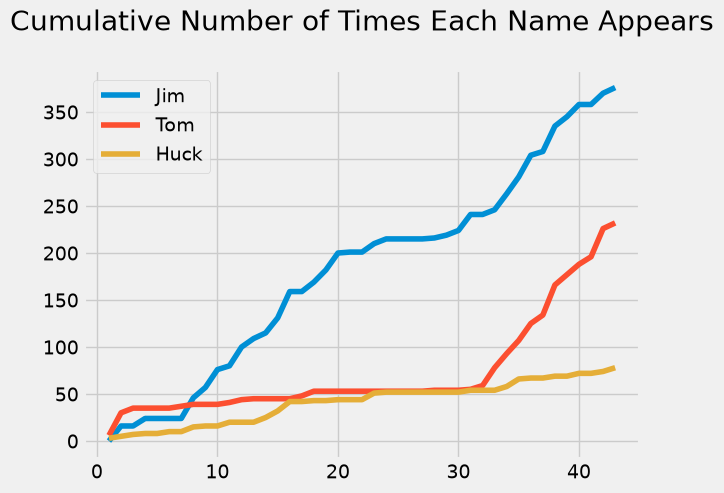

In [3]:
# Get the cumulative counts the names Jim, Tom, and Huck appear in each chapter.

# POLARS_CHANGE: count_matches treats the pattern as a regular expression unless literal=True
huck_finn = pl.Series("chapter", huck_finn_chapters)
counts = pl.DataFrame([
    huck_finn.str.count_matches("Jim", literal=True).cum_sum().alias("Jim"),
    huck_finn.str.count_matches("Tom", literal=True).cum_sum().alias("Tom"),
    huck_finn.str.count_matches("Huck", literal=True).cum_sum().alias("Huck"),
])

# Plot the cumulative counts:
# how many times in Chapter 1, how many times in Chapters 1 and 2, and so on.

cum_counts = counts.with_columns(pl.Series("Chapter", range(1, 44)))
# POLARS_CHANGE: Polars does not plot, so each name is drawn against Chapter
for name in ["Jim", "Tom", "Huck"]:
    plots.plot(cum_counts.get_column("Chapter"), cum_counts.get_column(name), label=name)
plots.legend()
plots.title("Cumulative Number of Times Each Name Appears", y=1.08);

In the plot above, the horizontal axis shows chapter numbers and the vertical axis shows how many times each character has been mentioned up to and including that chapter. 

You can see that Jim is a central character by the large number of times his name appears. Notice how Tom is hardly mentioned for much of the book until he arrives and joins Huck and Jim, after Chapter 30. His curve and Jim's rise sharply at that point, as the action involving both of them intensifies. As for Huck, his name hardly appears at all, because he is the narrator. 

*Little Women* is a story of four sisters growing up together during the civil war. In this book, chapter numbers are spelled out and chapter titles are written in all capital letters.

In [4]:
# The chapters of Little Women, in a DataFrame

# POLARS_CHANGE: show enough of each chapter string to include the opening sentence
with pl.Config(fmt_str_lengths=160):
    display(pl.DataFrame([pl.Series("Chapters", little_women_chapters)]))

Chapters
str
"""ONE PLAYING PILGRIMS ""Christmas won't be Christmas without any presents,"" grumbled Jo, lying on the rug. ""It's so dreadful to be poor!"" sighed Meg, looking down…"
"""TWO A MERRY CHRISTMAS Jo was the first to wake in the gray dawn of Christmas morning. No stockings hung at the fireplace, and for a moment she felt as much disa…"
"""THREE THE LAURENCE BOY ""Jo! Jo! Where are you?"" cried Meg at the foot of the garret stairs. ""Here!"" answered a husky voice from above, and, running up, Meg foun…"
"""FOUR BURDENS ""Oh, dear, how hard it does seem to take up our packs and go on,"" sighed Meg the morning after the party, for now the holidays were over, the week …"
"""FIVE BEING NEIGHBORLY ""What in the world are you going to do now, Jo?"" asked Meg one snowy afternoon, as her sister came tramping through the hall, in rubber bo…"
…
"""FORTY-THREE SURPRISES Jo was alone in the twilight, lying on the old sofa, looking at the fire, and thinking. It was her favorite way of spending the hour of du…"
"""FORTY-FOUR MY LORD AND LADY ""Please, Madam Mother, could you lend me my wife for half an hour? The luggage has come, and I've been making hay of Amy's Paris fin…"
"""FORTY-FIVE DAISY AND DEMI I cannot feel that I have done my duty as humble historian of the March family, without devoting at least one chapter to the two most …"


We can track the mentions of main characters to learn about the plot of this book as well.  The protagonist Jo interacts with her sisters Meg, Beth, and Amy regularly, up until Chapter 27 when she moves to New York alone.

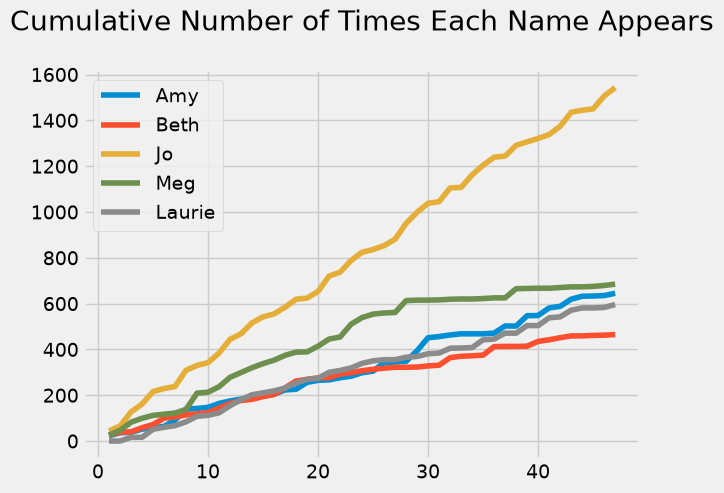

In [5]:
# Get the cumulative counts of the names in the chapters of Little Women

# POLARS_CHANGE: count_matches treats the pattern as a regular expression unless literal=True
little_women = pl.Series("chapter", little_women_chapters)
counts = pl.DataFrame([
    little_women.str.count_matches("Amy", literal=True).cum_sum().alias("Amy"),
    little_women.str.count_matches("Beth", literal=True).cum_sum().alias("Beth"),
    little_women.str.count_matches("Jo", literal=True).cum_sum().alias("Jo"),
    little_women.str.count_matches("Meg", literal=True).cum_sum().alias("Meg"),
    little_women.str.count_matches("Laurie", literal=True).cum_sum().alias("Laurie"),
])

# Plot the cumulative counts.

cum_counts = counts.with_columns(pl.Series("Chapter", range(1, 48)))
# POLARS_CHANGE: Polars does not plot, so each name is drawn against Chapter
for name in ["Amy", "Beth", "Jo", "Meg", "Laurie"]:
    plots.plot(cum_counts.get_column("Chapter"), cum_counts.get_column(name), label=name)
plots.legend()
plots.title("Cumulative Number of Times Each Name Appears", y=1.08);

Laurie is a young man who marries one of the girls in the end. See if you can use the plots to guess which one.